In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [17]:
# ====================== LOAD DATA ======================

data = pd.read_csv("../data/clustering_dataset.csv")
x = data.values

scaler = StandardScaler()
X = scaler.fit_transform(x)

print("Dataset shape:", X.shape)

Dataset shape: (12000, 2)


In [18]:
# ====================== DISTANCE + INIT ======================

def compute_distances(X, centroids):
    """
    Compute Euclidean distance between every point and centroid.
    Uses NumPy broadcasting for efficiency.
    """
    return np.sqrt(
        np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2, axis=2)
    )

def initialize_kmeans_plus_plus(X, k, random_state=None):
    """
    K-Means++ initialization:
    - First centroid randomly chosen
    - Next centroids chosen with probability proportional to squared distance
    """
    if random_state is not None:
        np.random.seed(random_state)

    n_samples = X.shape[0]
    centroids = [X[np.random.randint(n_samples)]]

    for _ in range(1, k):
        distances = compute_distances(X, np.array(centroids))
        min_dist = np.min(distances, axis=1)

        probs = min_dist ** 2
        probs /= probs.sum()

        next_idx = np.random.choice(n_samples, p=probs)
        centroids.append(X[next_idx])

    return np.array(centroids)

In [19]:
# ====================== CORE KMEANS ======================

def assign_clusters(X, centroids):
    return np.argmin(compute_distances(X, centroids), axis=1)

def update_centroids(X, labels, k):
    new_centroids = np.zeros((k, X.shape[1]))

    for i in range(k):
        cluster_points = X[labels == i]

        if len(cluster_points) == 0:
            # Handle empty cluster
            new_centroids[i] = X[np.random.randint(0, X.shape[0])]
        else:
            new_centroids[i] = cluster_points.mean(axis=0)

    return new_centroids

def compute_inertia(X, centroids, labels):
    inertia = 0.0
    for i in range(centroids.shape[0]):
        inertia += np.sum((X[labels == i] - centroids[i]) ** 2)
    return inertia

def kmeans(X, k, max_iters=100, tol=1e-4, init="kmeans++", random_state=None):

    if init == "random":
        centroids = X[np.random.choice(X.shape[0], k, replace=False)]
    else:
        centroids = initialize_kmeans_plus_plus(X, k, random_state)

    inertia_history = []

    for iteration in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, k)

        inertia = compute_inertia(X, new_centroids, labels)
        inertia_history.append(inertia)

        # Convergence check
        if np.linalg.norm(new_centroids - centroids) < tol:
            break

        centroids = new_centroids

    return centroids, labels, inertia, inertia_history

In [20]:
print("🚀 Running K-Means for k = 1 to 10...\n")

metrics_list = []
optimal_k = 2
best_sil = -np.inf

for k in range(1, 11):
    start = time.time()

    _, labels, final_inertia, inertia_history = kmeans(
        X, k=k, init="kmeans++", random_state=42
    )

    run_time = time.time() - start

    # Metrics (skip invalid cases)
    sil = silhouette_score(X, labels) if k > 1 else -1.0
    db  = davies_bouldin_score(X, labels) if k > 1 else np.inf
    ch  = calinski_harabasz_score(X, labels) if k > 1 else 0.0

    metrics_list.append({
        "model": "kmeans",
        "n_clusters": k,
        "epsilon": "",
        "min_pts": "",
        "inertia": round(final_inertia, 4),
        "silhouette": round(sil, 4),
        "davies_bouldin_score": round(db, 4),
        "calinski_harabasz_score": round(ch, 4),
        "n_noise": 0,
        "run_time": round(run_time, 4)
    })

    if sil > best_sil:
        best_sil = sil
        optimal_k = k

print(f"🏆 Optimal k = {optimal_k}")

🚀 Running K-Means for k = 1 to 10...

🏆 Optimal k = 3


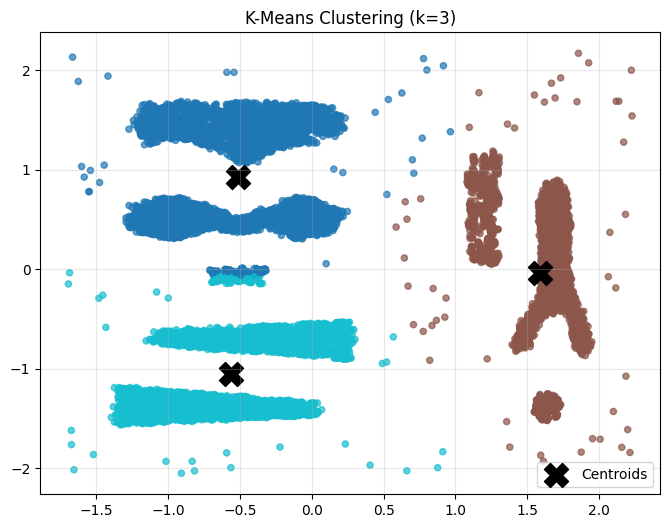

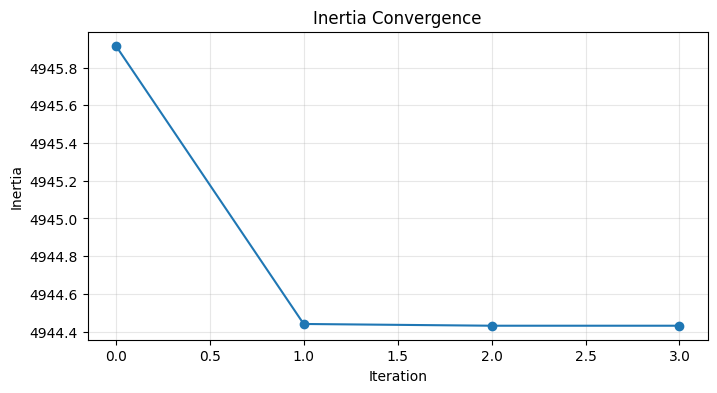

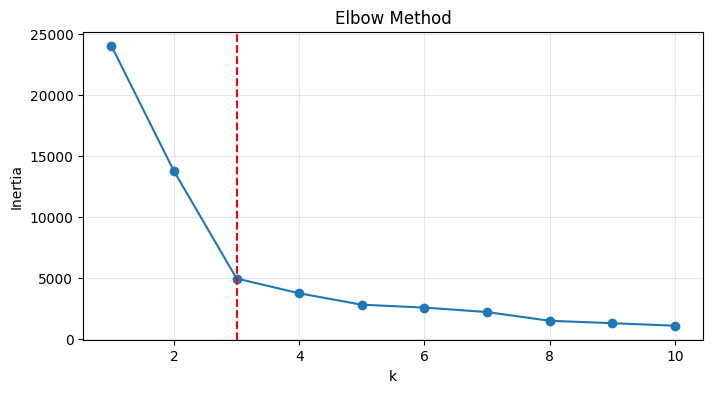

In [21]:
# Re-run optimal model
centroids, labels, final_inertia, inertia_history = kmeans(
    X, k=optimal_k, init="kmeans++", random_state=42
)

# --- Scatter Plot ---
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=20, alpha=0.7)
plt.scatter(centroids[:, 0], centroids[:, 1],
            c='black', marker='X', s=300, label='Centroids')
plt.title(f'K-Means Clustering (k={optimal_k})')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# --- Inertia Convergence ---
plt.figure(figsize=(8, 4))
plt.plot(inertia_history, marker='o')
plt.title("Inertia Convergence")
plt.xlabel("Iteration")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)
plt.show()

# --- Elbow Plot ---
k_values = [m["n_clusters"] for m in metrics_list]
inertias = [m["inertia"] for m in metrics_list]

plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, marker='o')
plt.axvline(optimal_k, color='red', linestyle='--')
plt.title("Elbow Method")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)
plt.show()

In [22]:
import os

# ====================== FINAL METRICS ======================

sil = silhouette_score(X, labels)
db  = davies_bouldin_score(X, labels)
ch  = calinski_harabasz_score(X, labels)

optimal_row = pd.DataFrame([{
    "model": "kmeans",
    "n_clusters": optimal_k,
    "epsilon": "",
    "min_pts": "",
    "inertia": round(final_inertia, 4),
    "silhouette": round(sil, 4),
    "davies_bouldin_score": round(db, 4),
    "calinski_harabasz_score": round(ch, 4),
    "n_noise": 0,
    "run_time": round(metrics_list[optimal_k-1]["run_time"], 4)
}])

file_path = "../results.csv"

# ====================== SAFE SAVE ======================

if not os.path.exists(file_path):
    # File does NOT exist → create with headers
    optimal_row.to_csv(file_path, index=False)
    print("📁 results.csv created and metrics saved.")
else:
    # File exists → append WITHOUT overwriting
    optimal_row.to_csv(file_path, mode='a', header=False, index=False)
    print("➕ Metrics appended to existing results.csv.")

print("\nSaved row:")
print(optimal_row.to_string(index=False))


📁 results.csv created and metrics saved.

Saved row:
 model  n_clusters epsilon min_pts   inertia  silhouette  davies_bouldin_score  calinski_harabasz_score  n_noise  run_time
kmeans           3                 4944.4308      0.6039                0.5721               23117.8948        0    0.0254
